# Logistic Regression with Python

For this lecture we will be working with the Titanic Survival problem. This is a very famous data set and very often is a student's first step in machine learning! 

We'll be trying to predict a classification- survival or deceased.
Let's begin our understanding of implementing Logistic Regression in Python for classification.

We'll use a "semi-cleaned" version of the titanic data set, if you use the data set hosted directly on Kaggle, you may need to do some additional cleaning not shown in this lecture notebook.

## Import Libraries
Let's import some libraries to get started!

# Logistic Regression in Machine Learning



Logistic regression is one of the most popular Machine Learning algorithms, which comes under the Supervised Learning technique. It is used for predicting the categorical dependent variable using a given set of independent variables.

Logistic regression predicts the output of a categorical dependent variable. Therefore the outcome must be a categorical or discrete value. It can be either Yes or No, 0 or 1, true or False, etc. but instead of giving the exact value as 0 and 1, it gives the probabilistic values which lie between 0 and 1.

Logistic Regression is much similar to the Linear Regression except that how they are used. Linear Regression is used for solving Regression problems, whereas Logistic regression is used for solving the classification problems.

In Logistic regression, instead of fitting a regression line, we fit an "S" shaped logistic function, which predicts two maximum values (0 or 1).

The curve from the logistic function indicates the likelihood of something such as whether the cells are cancerous or not, a mouse is obese or not based on its weight, etc.

Logistic Regression is a significant machine learning algorithm because it has the ability to provide probabilities and classify new data using continuous and discrete datasets.

Logistic Regression can be used to classify the observations using different types of data and can easily determine the most effective variables used for the classification. The below image is showing the logistic function:
Logistic Regression in Machine Learning


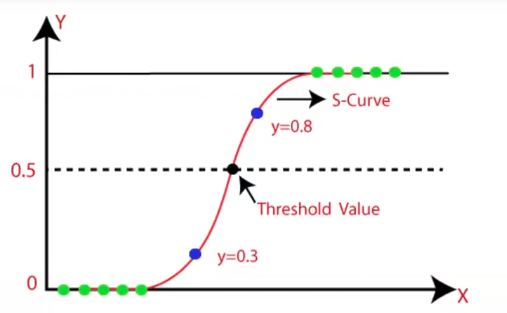

### Logistic regression uses the concept of predictive modeling as regression; therefore, it is called logistic regression, but is used to classify samples; Therefore, it falls under the classification algorithm.

### Logistic Function (Sigmoid Function):
The sigmoid function is a mathematical function used to map the predicted values to probabilities.

It maps any real value into another value within a range of 0 and 1.

The value of the logistic regression must be between 0 and 1, which cannot go beyond this limit, so it forms a curve like the "S" form. The S-form curve is called the Sigmoid function or the logistic function.

In logistic regression, we use the concept of the threshold value, which defines the probability of either 0 or 1. Such as values above the threshold value tends to 1, and a value below the threshold values tends to 0.


**Assumptions for Logistic Regression:**

The dependent variable must be categorical in nature.

The independent variable should not have multi-collinearity.

### Logistic Regression Equation:
The Logistic regression equation can be obtained from the Linear Regression equation. The mathematical steps to get Logistic Regression equations are given below:

We know the equation of the straight line can be written as:
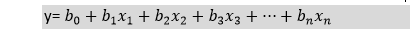

Logistic Regression in Machine Learning
In Logistic Regression y can be between 0 and 1 only, so for this let's divide the above equation by (1-y):
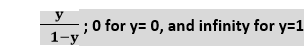

Logistic Regression in Machine Learning
But we need range between -[infinity] to +[infinity], then take logarithm of the equation it will become:
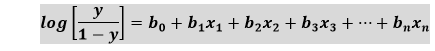

Logistic Regression in Machine Learning

### Type of Logistic Regression:
On the basis of the categories, Logistic Regression can be classified into three types:

Binomial: In binomial Logistic regression, there can be only two possible types of the dependent variables, such as 0 or 1, Pass or Fail, etc.

Multinomial: In multinomial Logistic regression, there can be 3 or more possible unordered types of the dependent variable, such as "cat", "dogs", or "sheep"

Ordinal: In ordinal Logistic regression, there can be 3 or more possible ordered types of dependent variables, such as "low", "Medium", or "High".

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

In [ ]:
### Predict survival on the Titanic ship
### Given a passenger data , can we predict if he/she can survive or not

## The Data

Let's start by reading in the titanic_train.csv file into a pandas dataframe.

In [ ]:
train = pd.read_csv('titanic_train.csv')
train.head()

In [ ]:
train.shape

In [ ]:
train.sample(n=500)

In [ ]:
train.info()

In [ ]:
train.shape

In [ ]:
train.describe()

In [ ]:
train.describe(include=object)

# Exploratory Data Analysis

Let's begin some exploratory data analysis! We'll start by checking out missing data!

## Missing Data

We can use seaborn to create a simple heatmap to see where we are missing data!

In [ ]:
train.isnull().sum()

train.isnull() creates a True/False DataFrame showing where data is missing.

sns.heatmap() visualizes it:

Yellow/Light color → Missing values (True)

Dark color → No missing values (False)

yticklabels=False: Hides row labels to keep the chart clean.

cbar=False: Removes the color bar.

cmap='viridis': Applies the Viridis color palette (nice color gradient).

In [ ]:
sns.heatmap(train.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [ ]:
percent_missing=train.isnull().sum()*100/len(train)
percent_missing

In [ ]:
missing_perct_df=pd.DataFrame({"col_name":train.columns,"% missing":percent_missing})
# missing_perct_df.head(11)
missing_perct_df.sort_values(by="% missing",ascending=False)

In [ ]:
train.isnull().sum()

Roughly 20 percent of the Age data is missing. The proportion of Age missing is likely small enough for reasonable replacement with some form of imputation. Looking at the Cabin column, it looks like we are just missing too much of that data to do something useful with at a basic level. We'll probably drop this later, or change it to another feature like "Cabin Known: 1 or 0"



In [ ]:
sns.set_style('whitegrid')
sns.countplot(x='Survived',data=train,palette='RdBu_r')

In [ ]:
# Above plot says that nonsurvied is more than survive



In [ ]:
sns.set_style('whitegrid')
sns.countplot(x='Survived',hue='Sex',data=train,palette='RdBu_r')

In [ ]:
#Insght: as wen can see female tends to survive more than males.
    

In [ ]:
sns.set_style('whitegrid')
sns.countplot(x='Survived',hue='Pclass',data=train,palette='rainbow')

In [ ]:
sns.distplot(train['Age'].dropna(),kde=True,color='darkred',bins=30)

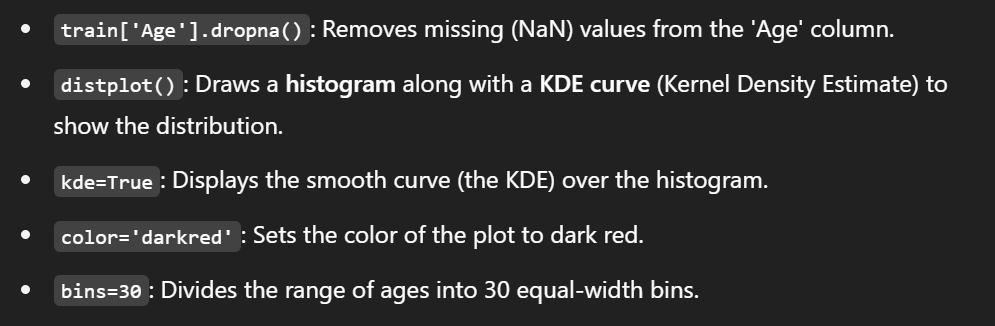

In [ ]:
train['Age'].hist(bins=30,color='darkred',alpha=0.7)

In [ ]:
sns.countplot(x='SibSp',data=train)

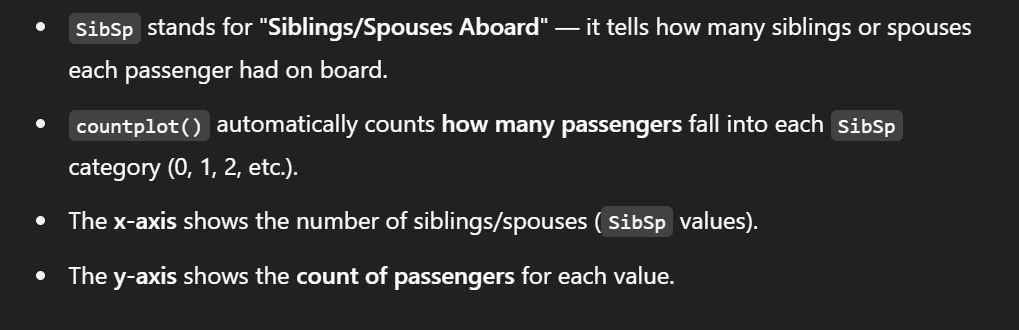

In [ ]:
train['Fare'].hist(color='green',bins=40,figsize=(8,4))

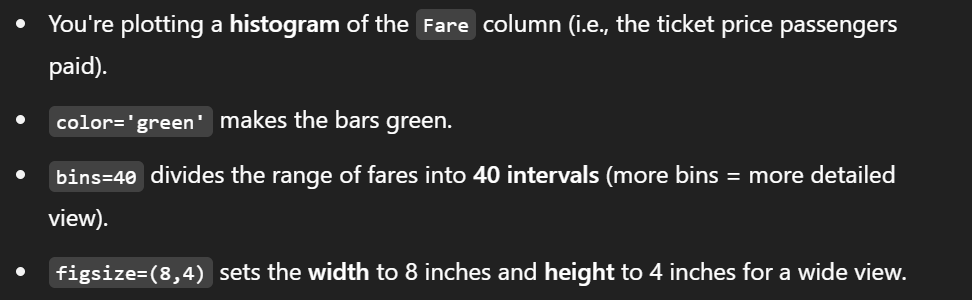


You’ll likely see that most fares are low (many people paid cheaper tickets).

A few passengers paid very high fares (outliers — rich people, 1st-class passengers).

Helps you detect skewness in data — Fare is usually right-skewed (more small values, few large ones).

___
## Data Cleaning
We want to fill in missing age data instead of just dropping the missing age data rows. One way to do this is by filling in the mean age of all the passengers (imputation).
However we can be smarter about this and check the average age by passenger class. For example:


In [ ]:
plt.figure(figsize=(12, 7))
sns.boxplot(x='Pclass',y='Age',data=train,palette='tab10')

We can see the wealthier passengers in the higher classes tend to be older, which makes sense. We'll use these average age values to impute based on Pclass for Age.

In [ ]:
train.head()

In [ ]:
def impute_age(cols):
    Age = cols[0]
    Pclass = cols[1]
    
    if pd.isnull(Age):

        if Pclass == 1:
            return 37

        elif Pclass == 2:
            return 29

        else:
            return 24

    else:
        return Age

Now apply that function!

In [ ]:
train['Age'] = train[['Age','Pclass']].apply(impute_age,axis=1)
train.head()

Now let's check that heat map again!

In [ ]:
sns.heatmap(train.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [ ]:
train.info()

Great! Let's go ahead and drop the Cabin column and the row in Embarked that is NaN.

In [ ]:
train.drop('Cabin',axis=1,inplace=True)

In [ ]:
train.head()

In [ ]:
train.dropna(inplace=True)

## Converting Categorical Features 

We'll need to convert categorical features to dummy variables using pandas! Otherwise our machine learning algorithm won't be able to directly take in those features as inputs.

In [ ]:
train.info()

In [ ]:
train["Sex"].value_counts()

In [ ]:
train["Embarked"].value_counts()

In [ ]:
train.head()

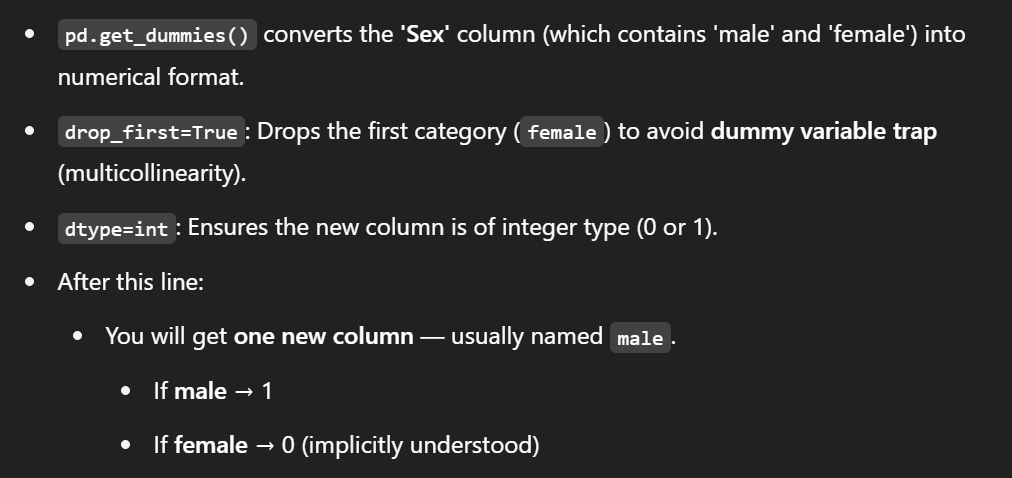

In [ ]:
sex = pd.get_dummies(train['Sex'],drop_first=True,dtype=int)
sex

In [ ]:
embark = pd.get_dummies(train['Embarked'],drop_first=True,dtype=int)

In [ ]:
embark.head()

In [ ]:
train.head(11)


In [ ]:
train.drop(['PassengerId','Sex','Embarked','Name','Ticket'],axis=1,inplace=True)

In [ ]:
train.head()

In [ ]:
train = pd.concat([train,sex,embark],axis=1)

In [ ]:
train.head(11)


In [ ]:
train.shape

Great! Our data is ready for our model!

# Building a Logistic Regression model

Let's start by splitting our data into a training set and test set (there is another test.csv file that you can play around with in case you want to use all this data for training).

## Train Test Split

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
train.shape

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(train.drop('Survived',axis=1), 
                                         train['Survived'], test_size=0.30, 
                                                    random_state=76)

In [ ]:
train.head()

In [ ]:
X_train.head()

In [ ]:
X_train.shape

In [ ]:
X_train.head()

In [ ]:
y_test.head()

## Training and Predicting

In [ ]:
# 1.import the model from sklearn
from sklearn.linear_model import LogisticRegression

# 2.Initilize
logmodel = LogisticRegression()

# 3.train
logmodel.fit(X_train,y_train)


# 4.predict
predictions = logmodel.predict(X_test)

In [ ]:
predictions[:5]

In [ ]:
y_test[:5]

In [ ]:
predictions_prob = logmodel.predict_proba(X_test)
predictions_prob

Let's move on to evaluate our model!

## Evaluation

We can check precision,recall,f1-score using classification report!

In [ ]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score 

In [ ]:
results = confusion_matrix(y_test, predictions) 

results

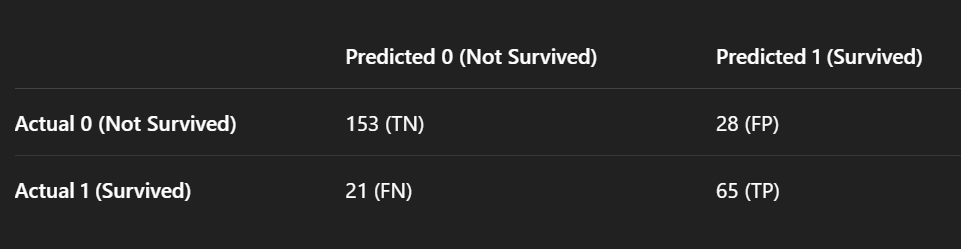

True Negative (TN) = 153 → Correctly predicted NOT survived

False Positive (FP) = 28 → Incorrectly predicted survived

False Negative (FN) = 21 → Incorrectly predicted NOT survived

True Positive (TP) = 65 → Correctly predicted survived

In [ ]:
accuracy_score(y_test, predictions)

In [ ]:
y_test[:10]

In [ ]:
predictions[:10]

In [ ]:
print(classification_report(y_test,predictions))

In [ ]:
from sklearn .metrics import roc_auc_score
from sklearn.metrics import roc_curve



auc = np.round(roc_auc_score(y_test, predictions), 3)

print("Auc for our sample data is {}". format(auc))


In [ ]:
fpr1, tpr1, thresh1 = roc_curve(y_test, predictions, pos_label=1)
thresh1

In [ ]:
from sklearn.metrics import roc_curve

# matplotlib
import matplotlib.pyplot as plt

fpr1, tpr1, thresh1 = roc_curve(y_test, predictions, pos_label=1)
fpr2, tpr2, thresh2 = roc_curve(y_test, predictions, pos_label=1)

# roc curve for tpr = fpr 
random_probs = [0 for i in range(len(y_test))]
p_fpr, p_tpr, _ = roc_curve(y_test, random_probs, pos_label=1)

# plot roc curves
plt.plot(fpr1, tpr1, linestyle='--',color='orange', label='Logistic Regression')
plt.plot(p_fpr, p_tpr, linestyle='--', color='blue')
# title
plt.title('ROC curve')
# x label
plt.xlabel('False Positive Rate')
# y label
plt.ylabel('True Positive rate')

plt.legend(loc='best')
plt.savefig('ROC',dpi=300)
plt.show()

Not so bad! You might want to explore other feature engineering and the other titanic_text.csv file, some suggestions for feature engineering:

* Try grabbing the Title (Dr.,Mr.,Mrs,etc..) from the name as a feature
* Maybe the Cabin letter could be a feature
* Is there any info you can get from the ticket?

## Great Job!